# 06. Logistic Regression — Future Customer Purchase Prediction

**Project:** E-Commerce Customer Analytics  
**Objective:** Predict the probability that an existing customer will make **at least one valid purchase** (`will_purchase = 1`) during the upcoming **90-day Q4 target period**, using strictly pre-cutoff historical behavior and complete future observation windows.

> **Anti-Leakage & Observability Rules:**
> - **Eligibility at Cutoff:** Every included customer made at least one purchase during the **275-day observation period** (`2009-12-10`–`2010-09-10` for Train; `2010-12-10`–`2011-09-10` for Test).
> - **Complete Future Target Windows:** Target periods (`2010-09-11`–`2010-12-09` for Train; `2011-09-11`–`2011-12-09` for Test) lie **entirely inside** the observed dataset (`<= 2011-12-09`), ensuring non-purchasers (`0`) are true non-purchasers rather than right-censored records.
> - **Zero Overlap:** Train (`<= 2010-12-09`) and Test (`>= 2010-12-10`) are strictly disjoint in time.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import precision_recall_curve, roc_curve

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models.classification import (
    TARGET_CLASS_COLUMN,
    build_purchase_classification_cohort,
    evaluate_classification_suite,
)
from src.models.regression import FEATURE_COLUMNS

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

TX_PATH = PROJECT_ROOT / "dataset" / "processed" / "analytics" / "transaction_features.csv"
VIZ_DIR = PROJECT_ROOT / "visualizations"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
for d in (VIZ_DIR, MODELS_DIR, REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

tx_df = pd.read_csv(
    TX_PATH,
    dtype={"invoice": "string", "stock_code": "string", "customer_id": "Int64"},
    parse_dates=["invoice_date"],
)

train_df = build_purchase_classification_cohort(tx_df, "2009-12-10", "2010-09-11", "2010-09-11", "2010-12-10")
test_df = build_purchase_classification_cohort(tx_df, "2010-12-10", "2011-09-11", "2011-09-11", "2011-12-10")

balance_df = pd.DataFrame([
    ("Train (2010 Q4)", len(train_df), int((train_df[TARGET_CLASS_COLUMN] == 1).sum()), int((train_df[TARGET_CLASS_COLUMN] == 0).sum()), round(float(train_df[TARGET_CLASS_COLUMN].mean() * 100), 2)),
    ("Test  (2011 Q4)", len(test_df), int((test_df[TARGET_CLASS_COLUMN] == 1).sum()), int((test_df[TARGET_CLASS_COLUMN] == 0).sum()), round(float(test_df[TARGET_CLASS_COLUMN].mean() * 100), 2)),
], columns=["Cohort", "Total Customers", "Purchasers (1)", "Non-Purchasers (0)", "Positive Rate (%)"])
display(balance_df)

print("Missing values in features/target (Train / Test):",
      int(train_df[FEATURE_COLUMNS + [TARGET_CLASS_COLUMN]].isna().sum().sum()),
      "/",
      int(test_df[FEATURE_COLUMNS + [TARGET_CLASS_COLUMN]].isna().sum().sum()))
display(train_df[["customer_id"] + FEATURE_COLUMNS + [TARGET_CLASS_COLUMN]].head(6))

,Cohort,Total Customers,Purchasers (1),Non-Purchasers (0),Positive Rate (%)
0,Train (2010 Q4),3270,1908,1362,58.35
1,Test (2011 Q4),3248,1872,1376,57.64


Missing values in features/target (Train / Test): 0 / 0


,customer_id,hist_spending,hist_frequency,hist_quantity,hist_aov,hist_unique_products,hist_recency,hist_tenure,hist_cancelled_orders,will_purchase
0,12346,-146.24,2,10,-73.12,24,75,193,1,0
1,12349,1268.52,2,474,634.26,47,116,135,0,1
2,12355,488.21,1,303,488.21,22,113,113,0,0
3,12358,268.10,1,281,268.10,17,96,96,0,1
4,12359,1157.34,4,264,289.33,52,81,269,2,1
5,12360,740.04,3,755,246.68,44,109,201,1,1


### Classification Cohorts & Class Balance Analysis
- Both cohorts maintain nearly identical, well-populated class balance across consecutive years:
  - **Train (`n = 3,270`):** **`58.35%`** (`1,908`) made at least one purchase in 2010 Q4 vs. **`41.65%`** (`1,362`) who did not.
  - **Test (`n = 3,248`):** **`57.64%`** (`1,872`) made at least one purchase in 2011 Q4 vs. **`42.36%`** (`1,376`) who did not.
- Notice why **Accuracy alone is misleading**: a naive Majority-Class Baseline that blindly predicts `1` for every customer automatically achieves **`57.64%` accuracy** and **`0.7312` F1-score** while catching **`0%` of non-purchasers** (`ROC-AUC = 0.5000`, `PR-AUC = 0.5764`)!

Discovered Thresholds (strictly via 5-fold CV on Train): {'default': 0.5, 'balanced_accuracy': 0.56, 'max_f1': 0.34}

Full Model Evaluation Comparison:


,model_name,split,threshold,n_samples,accuracy,balanced_accuracy,precision,recall,f1_score,roc_auc,pr_auc,tn,fp,fn,tp
0,Baseline (Majority Class),test,0.50,3248,0.5764,0.5000,0.5764,1.0000,0.7312,0.5000,0.5764,0,1376,0,1872
1,Logistic Regression (Raw Scaled),test,0.50,3248,0.6881,0.6846,0.7398,0.7078,0.7235,0.7475,0.8149,910,466,547,1325
2,Logistic Regression (Signed-Log1p),train_oof_cv,0.50,3270,0.6670,0.6559,0.7114,0.7222,0.7168,0.7243,0.7918,803,559,530,1378
3,Logistic Regression (Signed-Log1p),train_full,0.50,3270,0.6673,0.6557,0.7107,0.7248,0.7177,0.7267,0.7936,799,563,525,1383
4,"Logistic Regression (Signed-Log1p, thr=0.50)",test,0.50,3248,0.6832,0.6749,0.7234,0.7292,0.7263,0.7471,0.8178,854,522,507,1365
5,Logistic Regression (Balanced thr=0.56),test,0.56,3248,0.6786,0.6824,0.7534,0.6576,0.7022,0.7471,0.8178,973,403,641,1231
6,Logistic Regression (Max-F1 thr=0.34),test,0.34,3248,0.6155,0.5548,0.6059,0.9519,0.7405,0.7471,0.8178,217,1159,90,1782


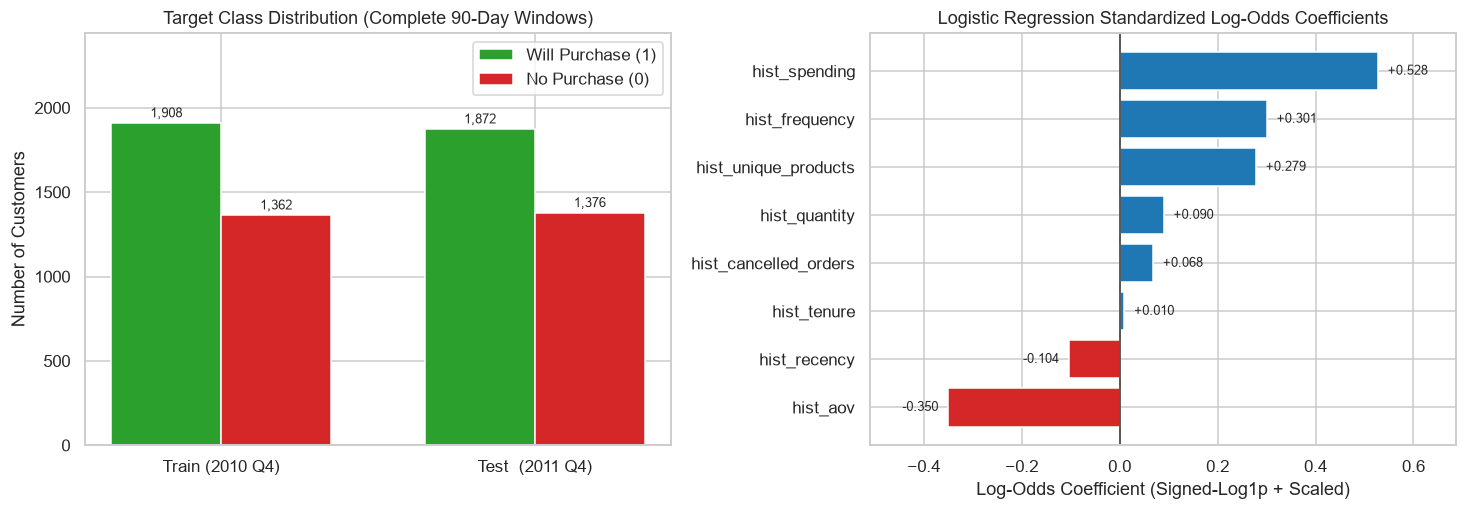

In [2]:
model_pipe, eval_df, thresholds, pred_df = evaluate_classification_suite(train_df, test_df, FEATURE_COLUMNS)
print("Discovered Thresholds (strictly via 5-fold CV on Train):", thresholds)
print("\nFull Model Evaluation Comparison:")
display(eval_df)

# Chart 1: Class Distribution & Standardized Log-Odds Coefficients
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

x = np.arange(len(balance_df))
w = 0.35
axes[0].bar(x - w / 2, balance_df["Purchasers (1)"], width=w, color="#2ca02c", label="Will Purchase (1)")
axes[0].bar(x + w / 2, balance_df["Non-Purchasers (0)"], width=w, color="#d62728", label="No Purchase (0)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(balance_df["Cohort"])
axes[0].set_ylabel("Number of Customers")
axes[0].set_title("Target Class Distribution (Complete 90-Day Windows)")
axes[0].legend(loc="upper right")
for idx, (p_cnt, n_cnt) in enumerate(zip(balance_df["Purchasers (1)"], balance_df["Non-Purchasers (0)"])):
    axes[0].text(idx - w / 2, p_cnt + 35, f"{p_cnt:,}", ha="center", fontsize=8.5)
    axes[0].text(idx + w / 2, n_cnt + 35, f"{n_cnt:,}", ha="center", fontsize=8.5)
axes[0].set_ylim(0, balance_df["Purchasers (1)"].max() * 1.28)

clf = model_pipe.named_steps["classifier"]
coefs = pd.Series(clf.coef_[0], index=FEATURE_COLUMNS).sort_values()
c_colors = ["#d62728" if v < 0 else "#1f77b4" for v in coefs.values]
bars_c = axes[1].barh(coefs.index, coefs.values, color=c_colors)
axes[1].axvline(0, color="#333333", linewidth=1)
axes[1].set_title("Logistic Regression Standardized Log-Odds Coefficients")
axes[1].set_xlabel("Log-Odds Coefficient (Signed-Log1p + Scaled)")
for b, v in zip(bars_c, coefs.values):
    off = 0.02 if v >= 0 else -0.02
    ha = "left" if v >= 0 else "right"
    axes[1].text(v + off, b.get_y() + b.get_height() / 2, f"{v:+.3f}", va="center", ha=ha, fontsize=8.5)
axes[1].set_xlim(coefs.min() - 0.16, coefs.max() + 0.16)

plt.tight_layout()
fig.savefig(VIZ_DIR / "06_logreg_class_and_coeffs.png", dpi=150, bbox_inches="tight")
plt.show()

### Model Performance & Feature Coefficients Analysis
- **Model Gains Over Baseline:** On the unseen Test cohort (`n = 3,248`), the `Signed-Log1p + StandardScaler + LogisticRegression` pipeline reaches **`ROC-AUC = 0.7471`** (vs. `0.5000` baseline) and **`PR-AUC = 0.8178`** (vs. `0.5764` baseline), raising accuracy from `57.64%` to **`68.32%`** (`Precision = 72.34%`, `Recall = 72.92%`, `Balanced Accuracy = 67.49%` at `thr = 0.50`). Out-of-fold CV on Train (`ROC-AUC = 0.7243`) matches Test closely, confirming **zero overfitting**.
- **Interpreting the Log-Odds Weights:**
  - **Strongest Positive Signals:** Higher `hist_spending` (`+0.528`), `hist_frequency` (`+0.301`), and `hist_unique_products` (`+0.279`) strongly raise repeat-purchase odds.
  - **Negative Signals:** Longer `hist_recency` (`-0.104`, dormant customers are less likely to return) and higher `hist_aov` (`-0.350`, holding total spending fixed, one-off giant orders repeat less often than frequent smaller orders).

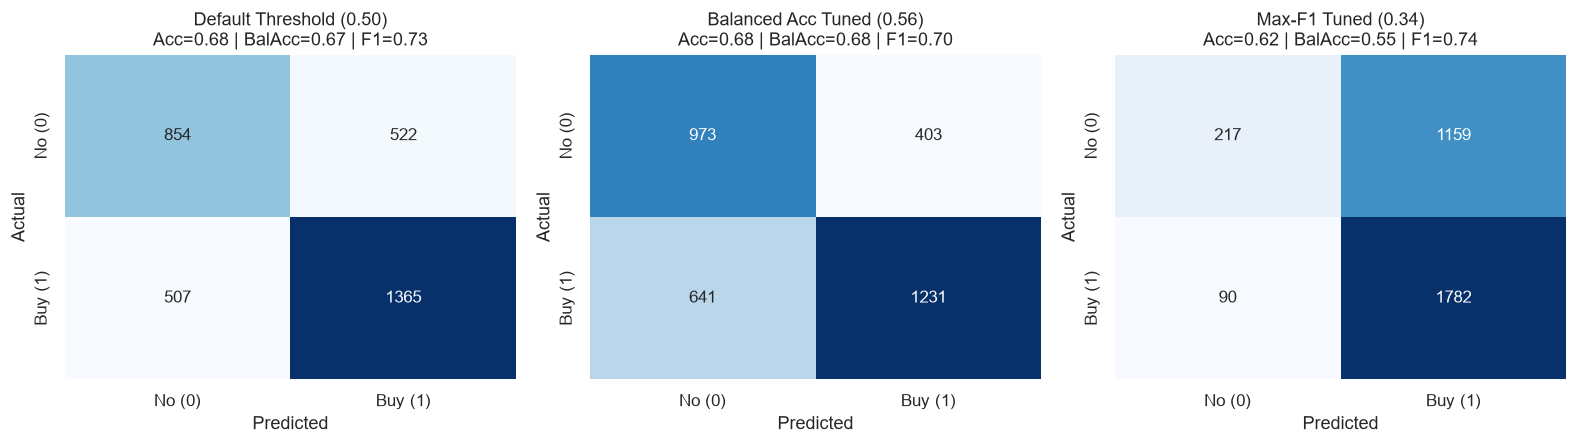

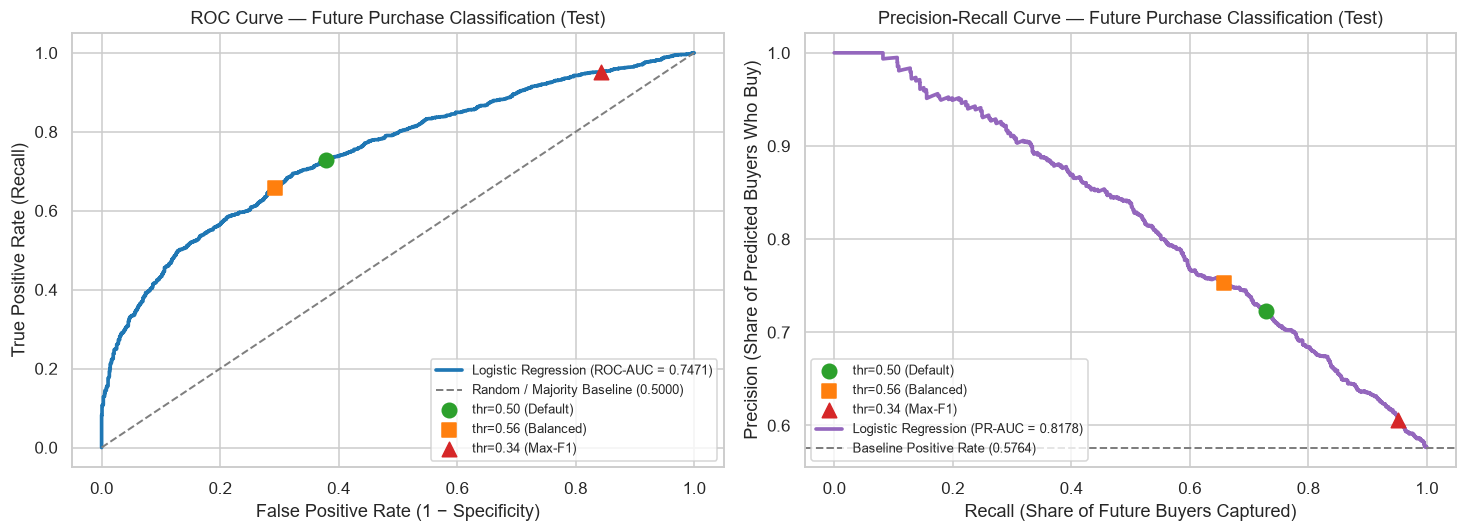

In [3]:
# Chart 2: Confusion Matrices across Default, Balanced-Accuracy, and Max-F1 Thresholds
thr_configs = [
    ("Default Threshold (0.50)", "pred_default_050", thresholds["default"]),
    (f"Balanced Acc Tuned ({thresholds['balanced_accuracy']:.2f})", "pred_balanced", thresholds["balanced_accuracy"]),
    (f"Max-F1 Tuned ({thresholds['max_f1']:.2f})", "pred_max_f1", thresholds["max_f1"]),
]

logreg_test_eval = eval_df[(eval_df["split"] == "test") & (eval_df["model_name"].str.startswith("Logistic Regression (Signed-Log1p") | eval_df["model_name"].str.startswith("Logistic Regression (Balanced") | eval_df["model_name"].str.startswith("Logistic Regression (Max-F1"))]

fig_cm, axes_cm = plt.subplots(1, 3, figsize=(14.5, 4.2))
for ax, (title, col, thr_val) in zip(axes_cm, thr_configs):
    cm = pd.crosstab(
        pred_df[TARGET_CLASS_COLUMN],
        pred_df[col],
        rownames=["Actual"],
        colnames=["Predicted"],
    ).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 11})
    row_info = logreg_test_eval[logreg_test_eval["threshold"] == thr_val].iloc[0]
    ax.set_title(f"{title}\nAcc={row_info['accuracy']:.2f} | BalAcc={row_info['balanced_accuracy']:.2f} | F1={row_info['f1_score']:.2f}")
    ax.set_xticklabels(["No (0)", "Buy (1)"])
    ax.set_yticklabels(["No (0)", "Buy (1)"])

plt.tight_layout()
fig_cm.savefig(VIZ_DIR / "06_logreg_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

# Chart 3: ROC Curve & Precision-Recall Curve with Operating Thresholds
y_test = pred_df[TARGET_CLASS_COLUMN].values
y_prob = pred_df["pred_probability"].values

fpr, tpr, roc_thrs = roc_curve(y_test, y_prob)
prec_curve, rec_curve, pr_thrs = precision_recall_curve(y_test, y_prob)

fig_curves, axes_c = plt.subplots(1, 2, figsize=(13.5, 5.0))

test_log_row = logreg_test_eval[logreg_test_eval["threshold"] == 0.50].iloc[0]
axes_c[0].plot(fpr, tpr, color="#1f77b4", linewidth=2.4, label=f"Logistic Regression (ROC-AUC = {test_log_row['roc_auc']:.4f})")
axes_c[0].plot([0, 1], [0, 1], color="#7f7f7f", linestyle="--", linewidth=1.3, label="Random / Majority Baseline (0.5000)")

# Mark operating points on ROC & PR curves
markers = [
    ("thr=0.50 (Default)", 0.50, "#2ca02c", "o"),
    (f"thr={thresholds['balanced_accuracy']:.2f} (Balanced)", thresholds["balanced_accuracy"], "#ff7f0e", "s"),
    (f"thr={thresholds['max_f1']:.2f} (Max-F1)", thresholds["max_f1"], "#d62728", "^"),
]
for label, t, color, mk in markers:
    sub = logreg_test_eval[logreg_test_eval["threshold"] == t].iloc[0]
    fpr_pt = sub["fp"] / (sub["fp"] + sub["tn"])
    axes_c[0].scatter([fpr_pt], [sub["recall"]], color=color, marker=mk, s=90, zorder=5, label=label)
    axes_c[1].scatter([sub["recall"]], [sub["precision"]], color=color, marker=mk, s=90, zorder=5, label=label)

axes_c[0].set_title("ROC Curve — Future Purchase Classification (Test)")
axes_c[0].set_xlabel("False Positive Rate (1 − Specificity)")
axes_c[0].set_ylabel("True Positive Rate (Recall)")
axes_c[0].legend(loc="lower right", fontsize=8.5)

axes_c[1].plot(rec_curve, prec_curve, color="#9467bd", linewidth=2.4, label=f"Logistic Regression (PR-AUC = {test_log_row['pr_auc']:.4f})")
axes_c[1].axhline(y_test.mean(), color="#7f7f7f", linestyle="--", linewidth=1.3, label=f"Baseline Positive Rate ({y_test.mean():.4f})")
axes_c[1].set_title("Precision-Recall Curve — Future Purchase Classification (Test)")
axes_c[1].set_xlabel("Recall (Share of Future Buyers Captured)")
axes_c[1].set_ylabel("Precision (Share of Predicted Buyers Who Buy)")
axes_c[1].legend(loc="lower left", fontsize=8.5)

plt.tight_layout()
fig_curves.savefig(VIZ_DIR / "06_logreg_roc_and_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Confusion Matrix, Threshold Trade-Offs, ROC & PR Curve Analysis
- **Operating Threshold Comparison (Tuned strictly on Train CV):**
  - **Default `0.50`:** Balanced operational profile (**`TN=854, FP=522, FN=507, TP=1,365`**), achieving `72.34%` Precision and `72.92%` Recall.
  - **Balanced-Accuracy Tuned (`0.56`):** Tightens false positives (`FP` drops from `522` to `403`), raising Precision to **`75.34%`** and Balanced Accuracy to **`68.24%`** (`Recall = 65.76%`). Ideal when marketing offers carry meaningful per-customer cost (e.g., printed catalogs or generous discount coupons).
  - **Max-F1 Tuned (`0.34`):** Because `58%` of customers are positives, maximizing raw F1 drops the threshold to `0.34`, pushing Recall to **`95.19%`** (`TP=1,782, FN=90`) at the cost of `1,159` false positives (`Precision = 60.59%`). Useful **only** for near-zero-cost digital email nudges.

In [4]:
MODEL_PATH = MODELS_DIR / "logistic_regression_pipeline.joblib"
RESULTS_PATH = REPORTS_DIR / "logistic_regression_results.csv"

joblib.dump(model_pipe, MODEL_PATH)
eval_df.to_csv(RESULTS_PATH, index=False, encoding="utf-8")

# Verify reloaded model predicts identical probabilities
reloaded_pipe = joblib.load(MODEL_PATH)
reloaded_probs = reloaded_pipe.predict_proba(test_df[FEATURE_COLUMNS])[:, 1]
assert np.allclose(reloaded_probs, model_pipe.predict_proba(test_df[FEATURE_COLUMNS])[:, 1])

# Inspect probability deciles for responsible ranking calibration check
cal_df = pred_df.copy()
cal_df["prob_bin"] = pd.qcut(cal_df["pred_probability"], q=5, labels=["Q1 (Lowest)", "Q2", "Q3", "Q4", "Q5 (Highest)"])
calib_summary = cal_df.groupby("prob_bin", observed=False).agg(
    customers=("customer_id", "count"),
    mean_pred_prob=("pred_probability", "mean"),
    actual_purchase_rate=(TARGET_CLASS_COLUMN, "mean"),
    avg_hist_spend=("hist_spending", "mean"),
).round(4)
print("Quintile Calibration & Ranking Verification (Test):")
display(calib_summary)

print(f"Saved model pipeline: {MODEL_PATH.relative_to(PROJECT_ROOT)} ({MODEL_PATH.stat().st_size / 1024:.2f} KB)")
print(f"Saved results CSV: {RESULTS_PATH.relative_to(PROJECT_ROOT)}")
display(pd.read_csv(RESULTS_PATH))

Quintile Calibration & Ranking Verification (Test):


,customers,mean_pred_prob,actual_purchase_rate,avg_hist_spend
prob_bin,,,,
Q1 (Lowest),650,0.3331,0.3308,188.3150
Q2,650,0.4331,0.4123,388.0782
Q3,650,0.5597,0.5385,664.4833
Q4,648,0.6957,0.6960,1208.0634
Q5 (Highest),650,0.8572,0.9046,4983.2712


Saved model pipeline: models\logistic_regression_pipeline.joblib (2.55 KB)
Saved results CSV: reports\logistic_regression_results.csv


,model_name,split,threshold,n_samples,accuracy,balanced_accuracy,precision,recall,f1_score,roc_auc,pr_auc,tn,fp,fn,tp
0,Baseline (Majority Class),test,0.50,3248,0.5764,0.5000,0.5764,1.0000,0.7312,0.5000,0.5764,0,1376,0,1872
1,Logistic Regression (Raw Scaled),test,0.50,3248,0.6881,0.6846,0.7398,0.7078,0.7235,0.7475,0.8149,910,466,547,1325
2,Logistic Regression (Signed-Log1p),train_oof_cv,0.50,3270,0.6670,0.6559,0.7114,0.7222,0.7168,0.7243,0.7918,803,559,530,1378
3,Logistic Regression (Signed-Log1p),train_full,0.50,3270,0.6673,0.6557,0.7107,0.7248,0.7177,0.7267,0.7936,799,563,525,1383
4,"Logistic Regression (Signed-Log1p, thr=0.50)",test,0.50,3248,0.6832,0.6749,0.7234,0.7292,0.7263,0.7471,0.8178,854,522,507,1365
5,Logistic Regression (Balanced thr=0.56),test,0.56,3248,0.6786,0.6824,0.7534,0.6576,0.7022,0.7471,0.8178,973,403,641,1231
6,Logistic Regression (Max-F1 thr=0.34),test,0.34,3248,0.6155,0.5548,0.6059,0.9519,0.7405,0.7471,0.8178,217,1159,90,1782


### Q&A
- **How were valid positive/negative labels created without leakage or right-censoring?** Every eligible customer (`n = 3,270` Train, `n = 3,248` Test) purchased during a complete **275-day historical window** and was tracked across a complete **90-day Q4 target window** ending on or before `2011-12-09`. Customers placing at least one valid purchase in the target period received label `1` (`58.35%` Train, `57.64%` Test); customers making zero purchases received label `0`.
- **Why is accuracy alone misleading, and how should businesses use the model?** A majority-class baseline reaches `57.64%` accuracy (`F1 = 0.7312`) while identifying zero non-buyers (`ROC-AUC = 0.5000`). Logistic Regression separates true buyers from non-buyers cleanly (**`ROC-AUC = 0.7471`**, **`PR-AUC = 0.8178`**), ranking customers monotonically from **`33.08%`** actual purchase rate in the lowest probability quintile up to **`90.46%`** in the highest quintile—making probability scores best suited for **campaign budget tiering and outreach prioritization** rather than deterministic guarantees.

### Data Analysis Key Findings
- **Generalized Classification Performance:** At default threshold `0.50`, the pipeline achieves **`68.32%` Accuracy**, **`72.34%` Precision**, **`72.92%` Recall**, **`0.7263` F1**, **`0.7471` ROC-AUC**, and **`0.8178` PR-AUC** on Test (`Train OOF ROC-AUC = 0.7243`, confirming minimal overfitting).
- **Threshold Trade-Offs:** CV-tuned threshold `0.56` boosts Precision to `75.34%` (Balanced Accuracy `68.24%`), whereas `0.34` lifts Recall to `95.19%` while flagging `1,159` false positives.
- **Model Limitations:** Linear log-odds boundaries cannot capture complex non-linear interactions (e.g., sudden seasonal reactivations or B2B contract shifts), guest checkouts lacking `Customer ID` (`22.3%` of transactions) cannot be scored, and predictions remain calibrated strictly to Q4 90-day purchase horizons.
- **Saved Outputs:** Exported `models/logistic_regression_pipeline.joblib` and `reports/logistic_regression_results.csv`, along with confusion matrices, ROC/PR curves, class distribution, and coefficient charts in `visualizations/`.

### Insights or Next Steps
- **Responsible Business Deployment:** Avoid auto-excluding low-probability customers (`< 0.35`) from low-cost digital retention messages; instead, match channel cost to predicted probability quintiles (reserve expensive discounts/catalogs for mid-to-high-propensity customers where incremental lift matters most, and monitor false-negative churn signals separately).
- **Next Step:** Combine purchase probability from `06_Logistic_Regression.ipynb` with RFM segmentation (`K-Means`) and expected spending models to deliver unified customer intelligence in the Streamlit dashboard.